# Задание 2 Методы исследования временных рядов

## 1 Подготовка датасета

In [1]:
packages <- c('zoo', 'tseries')
missing_packages <- setdiff(packages, rownames(installed.packages()))
if (length(missing_packages) > 0) {
    invisible(capture.output(install.packages(
        missing_packages, repos = "https://cloud.r-project.org", quiet = TRUE
    )))
}
suppressPackageStartupMessages(library(zoo))
suppressPackageStartupMessages(library(tseries))
options(repr.plot.width = 10, repr.plot.height = 5.5, repr.plot.res = 130)

In [2]:
url <- "https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-car-sales.csv"
data <- read.csv(url)
data$Month <- as.Date(paste0(data$Month, "-01"))
data <- data[order(data$Month), ]
data$Year <- as.integer(format(data$Month, "%Y"))
data$MonthNumber <- as.integer(format(data$Month, "%m"))
sales_ts <- ts(data$Sales, start = c(1960, 1), frequency = 12)
head(data)

,Month,Sales,Year,MonthNumber
,<date>,<int>,<int>,<int>
1,1960-01-01,6550,1960,1
2,1960-02-01,8728,1960,2
3,1960-03-01,12026,1960,3
4,1960-04-01,14395,1960,4
5,1960-05-01,14587,1960,5
6,1960-06-01,13791,1960,6


## 2 Свойства временного ряда

In [3]:
data.frame(
    Класс = paste(class(sales_ts), collapse = ", "),
    Частота = frequency(sales_ts),
    Начало = paste(start(sales_ts), collapse = "-"),
    Конец = paste(end(sales_ts), collapse = "-"),
    Наблюдений = nrow(data),
    Пропусков = sum(is.na(data)),
    Повторов_дат = sum(duplicated(data$Month))
)
window(sales_ts, start = c(1966, 1), end = c(1967, 12))

Класс,Частота,Начало,Конец,Наблюдений,Пропусков,Повторов_дат
<chr>,<dbl>,<chr>,<chr>,<int>,<int>,<int>
ts,12,1960-1,1968-12,108,0,0


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
1966,12674,12760,20249,22135,20677,19933,15388,15113,13401,16135,17562,14720
1967,12225,11608,20985,19692,24081,22114,14220,13434,13598,17187,16119,13713


## 3 Описательная статистика и группировка

In [4]:
data.frame(
    Среднее = mean(data$Sales), Медиана = median(data$Sales),
    Дисперсия = var(data$Sales), Отклонение = sd(data$Sales),
    Минимум = min(data$Sales), Максимум = max(data$Sales)
)
annual_stats <- aggregate(Sales ~ Year, data, function(x) {
    c(Среднее = mean(x), Дисперсия = var(x), Минимум = min(x), Максимум = max(x))
})
annual_stats <- data.frame(Год = annual_stats$Year, annual_stats$Sales, check.names = FALSE)
annual_stats
monthly_stats <- aggregate(Sales ~ MonthNumber, data, mean)
names(monthly_stats) <- c("Месяц", "Средние_продажи")
monthly_stats

Среднее,Медиана,Дисперсия,Отклонение,Минимум,Максимум
<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>
14595.11,14076,20477561,4525.214,5568,26099


Год,Среднее,Дисперсия,Минимум,Максимум
<int>,<dbl>,<dbl>,<dbl>,<dbl>
1960,10186.67,7904560,6550,14587
1961,10858.08,7884949,7237,15926
1962,12663.33,16597301,5568,20900
1963,13826.92,16860838,7962,20379
1964,15171.08,16573559,10306,22015
1965,17111.50,17529389,10895,23541
1966,16728.92,10930152,12674,22135
1967,16581.33,17529583,11608,24081
1968,18228.17,15290051,13210,26099


Месяц,Средние_продажи
<int>,<dbl>
1,10875.89
2,11563.11
3,17086.11
4,19278.22
5,20883.78
6,18288.00
7,13672.00
8,11578.56
9,10140.00


## 4 График продаж

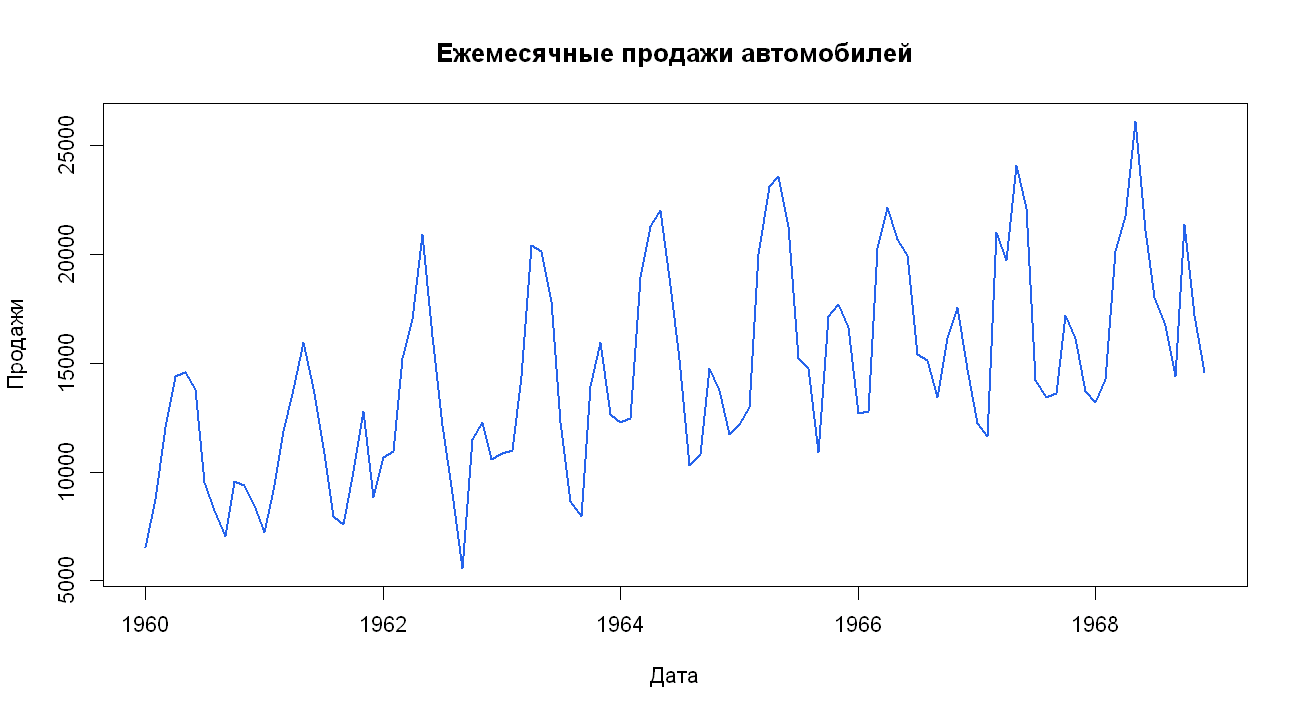

In [5]:
plot(data$Month, data$Sales, type = "l", col = "#2563EB", lwd = 2,
     xlab = "Дата", ylab = "Продажи", main = "Ежемесячные продажи автомобилей")

## 5 Гистограммы продаж и разностей

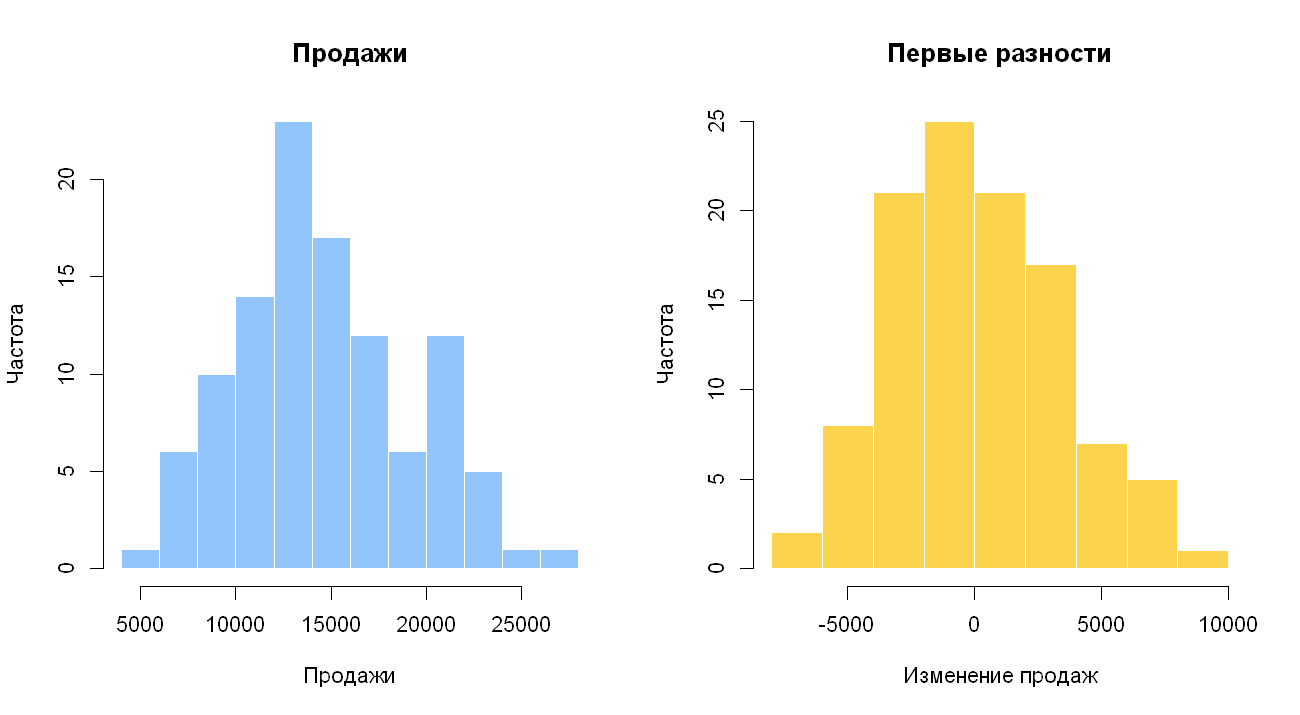

In [6]:
par(mfrow = c(1, 2))
hist(data$Sales, breaks = 12, col = "#93C5FD", border = "white",
     main = "Продажи", xlab = "Продажи", ylab = "Частота")
hist(diff(data$Sales), breaks = 12, col = "#FCD34D", border = "white",
     main = "Первые разности", xlab = "Изменение продаж", ylab = "Частота")
par(mfrow = c(1, 1))

## 6 Диаграммы рассеяния со сдвигом

Ряд,Корреляция_с_лагом_1
<chr>,<dbl>
Продажи,0.7280681
Первые разности,0.1568669


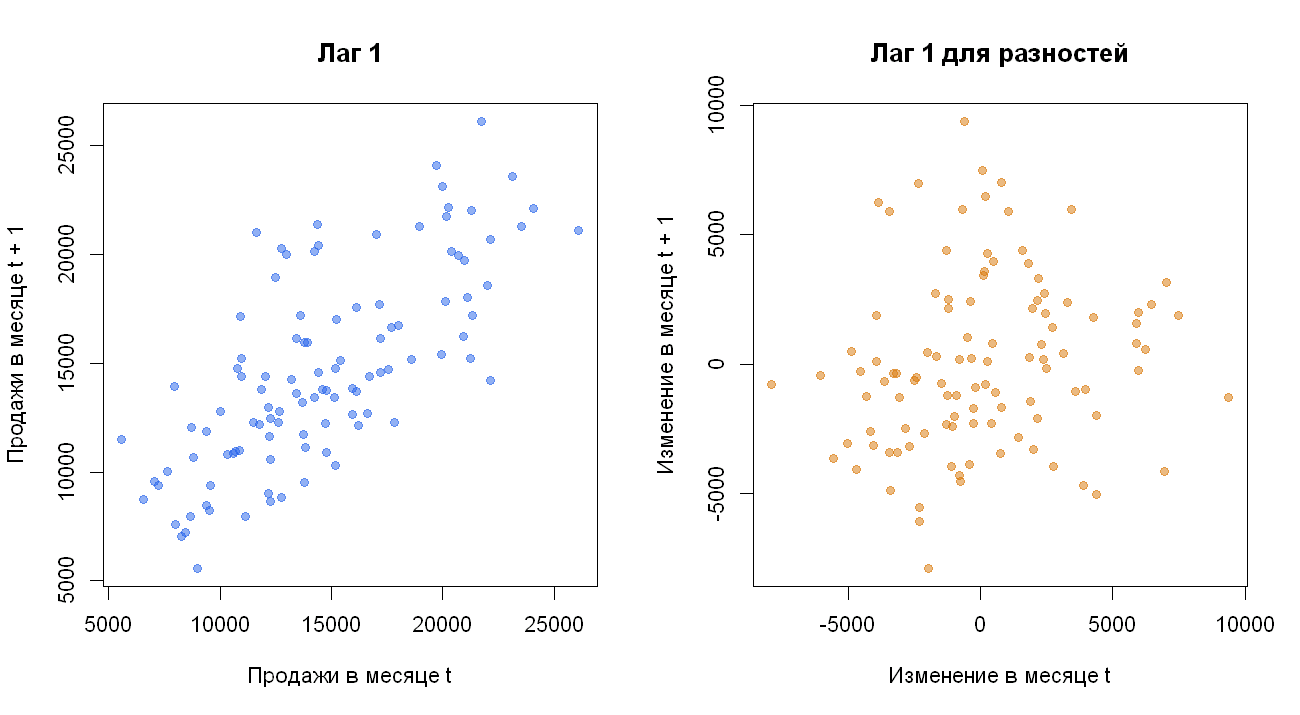

In [7]:
sales <- as.numeric(sales_ts)
changes <- diff(sales)
par(mfrow = c(1, 2))
plot(head(sales, -1), tail(sales, -1), pch = 19, col = "#2563EB80",
     xlab = "Продажи в месяце t", ylab = "Продажи в месяце t + 1", main = "Лаг 1")
plot(head(changes, -1), tail(changes, -1), pch = 19, col = "#D9770680",
     xlab = "Изменение в месяце t", ylab = "Изменение в месяце t + 1",
     main = "Лаг 1 для разностей")
par(mfrow = c(1, 1))
data.frame(
    Ряд = c("Продажи", "Первые разности"),
    Корреляция_с_лагом_1 = c(cor(head(sales, -1), tail(sales, -1)),
                            cor(head(changes, -1), tail(changes, -1)))
)

## 7 Преобразования ряда

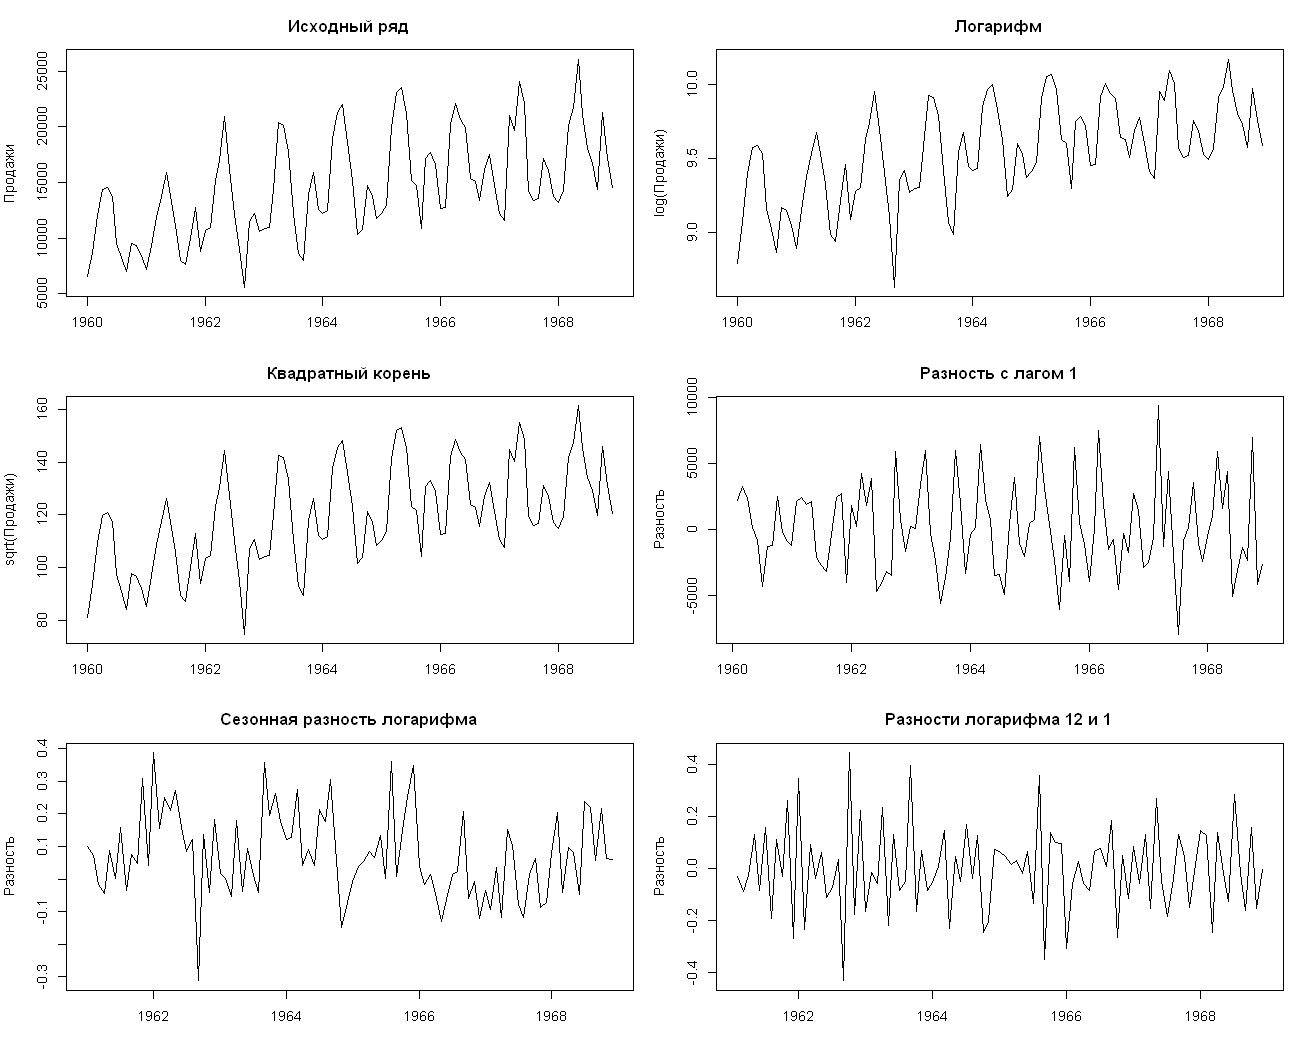

In [8]:
log_sales <- log(sales_ts)
sqrt_sales <- sqrt(sales_ts)
diff_sales <- diff(sales_ts)
seasonal_diff <- diff(sales_ts, lag = 12)
# Учёл годовую сезонность разностью с лагом 12.
seasonal_log_diff <- diff(log_sales, lag = 12)
combined_diff <- diff(seasonal_log_diff)

options(repr.plot.height = 8)
par(mfrow = c(3, 2), mar = c(3, 4, 3, 1))
plot(sales_ts, main = "Исходный ряд", xlab = "Год", ylab = "Продажи")
plot(log_sales, main = "Логарифм", xlab = "Год", ylab = "log(Продажи)")
plot(sqrt_sales, main = "Квадратный корень", xlab = "Год", ylab = "sqrt(Продажи)")
plot(diff_sales, main = "Разность с лагом 1", xlab = "Год", ylab = "Разность")
plot(seasonal_log_diff, main = "Сезонная разность логарифма", xlab = "Год", ylab = "Разность")
plot(combined_diff, main = "Разности логарифма 12 и 1", xlab = "Год", ylab = "Разность")
par(mfrow = c(1, 1))
options(repr.plot.height = 5.5)

## 8 Проверка стационарности ADF и KPSS

ADF: H₀ — единичный корень, с учётом линейного тренда. KPSS: H₀ — стационарность уровня. Уровень значимости 0,05.

In [9]:
format_p <- function(p, lower, upper) {
    if (p <= lower) return(paste0("<= ", lower))
    if (p >= upper) return(paste0(">= ", upper))
    format(round(p, 4), nsmall = 4)
}
check_stationarity <- function(x, name) {
    adf_p <- suppressWarnings(adf.test(as.numeric(x))$p.value)
    kpss_p <- suppressWarnings(kpss.test(as.numeric(x), null = "Level")$p.value)
    conclusion <- if (adf_p < 0.05 && kpss_p >= 0.05) {
        "Не противоречит стационарности"
    } else if (adf_p >= 0.05 && kpss_p < 0.05) {
        "Признаки нестационарности"
    } else {
        "Нет однозначного вывода"
    }
    data.frame(Ряд = name, ADF_p = format_p(adf_p, 0.01, 0.99),
               KPSS_p = format_p(kpss_p, 0.01, 0.1), Вывод = conclusion)
}
variants <- list(
    "Исходный ряд" = sales_ts, "Логарифм" = log_sales, "Корень" = sqrt_sales,
    "Разность 1" = diff_sales, "Разность 12" = seasonal_diff,
    "Сезонная разность логарифма" = seasonal_log_diff,
    "Разности логарифма 12 и 1" = combined_diff
)
stationarity_results <- do.call(rbind, lapply(names(variants), function(name) {
    check_stationarity(variants[[name]], name)
}))
rownames(stationarity_results) <- NULL
stationarity_results

Ряд,ADF_p,KPSS_p,Вывод
<chr>,<chr>,<chr>,<chr>
Исходный ряд,<= 0.01,<= 0.01,Нет однозначного вывода
Логарифм,<= 0.01,<= 0.01,Нет однозначного вывода
Корень,<= 0.01,<= 0.01,Нет однозначного вывода
Разность 1,<= 0.01,>= 0.1,Не противоречит стационарности
Разность 12,0.0215,>= 0.1,Не противоречит стационарности
Сезонная разность логарифма,0.0244,>= 0.1,Не противоречит стационарности
Разности логарифма 12 и 1,<= 0.01,>= 0.1,Не противоречит стационарности


## 9 Скользящее среднее

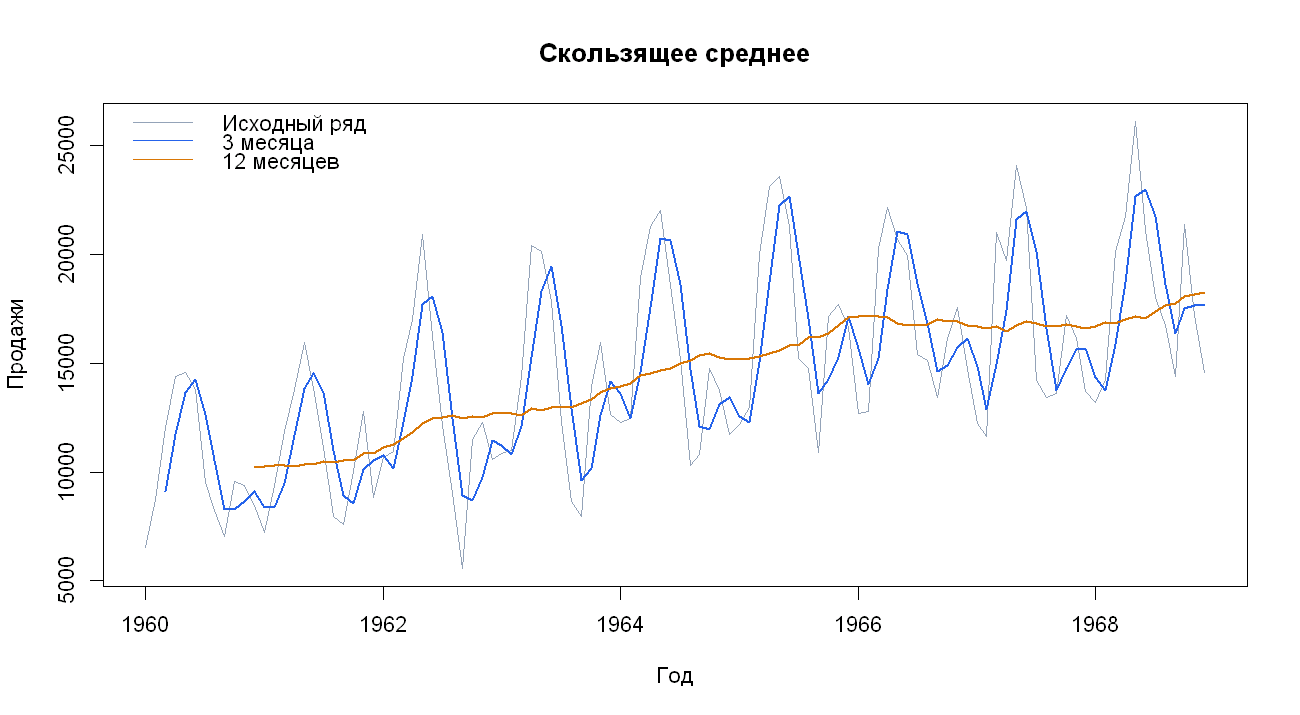

In [10]:
mean_3 <- stats::filter(sales_ts, rep(1 / 3, 3), sides = 1)
mean_12 <- stats::filter(sales_ts, rep(1 / 12, 12), sides = 1)
plot(sales_ts, col = "#94A3B8", xlab = "Год", ylab = "Продажи",
     main = "Скользящее среднее", lwd = 1)
lines(mean_3, col = "#2563EB", lwd = 2)
lines(mean_12, col = "#D97706", lwd = 2)
legend("topleft", c("Исходный ряд", "3 месяца", "12 месяцев"),
       col = c("#94A3B8", "#2563EB", "#D97706"), lty = 1, bty = "n")

## 10 Выравнивание скользящего окна

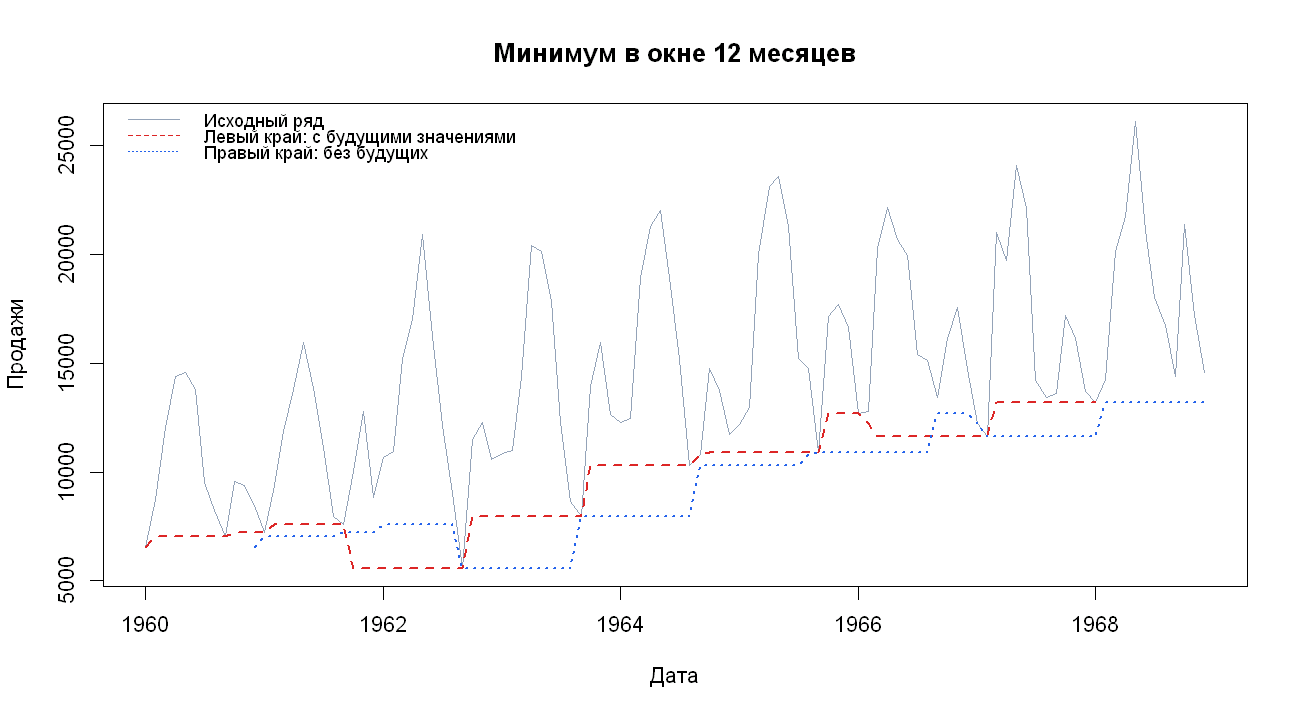

In [11]:
sales_zoo <- zoo(data$Sales, data$Month)
min_left <- rollapply(sales_zoo, 12, min, align = "left", fill = NA)
min_right <- rollapply(sales_zoo, 12, min, align = "right", fill = NA)
plot(sales_zoo, col = "#94A3B8", xlab = "Дата", ylab = "Продажи",
     main = "Минимум в окне 12 месяцев")
lines(min_left, col = "#DC2626", lwd = 2, lty = 2)
lines(min_right, col = "#2563EB", lwd = 2, lty = 3)
legend("topleft", c("Исходный ряд", "Левый край: с будущими значениями", "Правый край: без будущих"),
       col = c("#94A3B8", "#DC2626", "#2563EB"), lty = c(1, 2, 3), bty = "n", cex = 0.85)

## 11 Расширяющееся окно

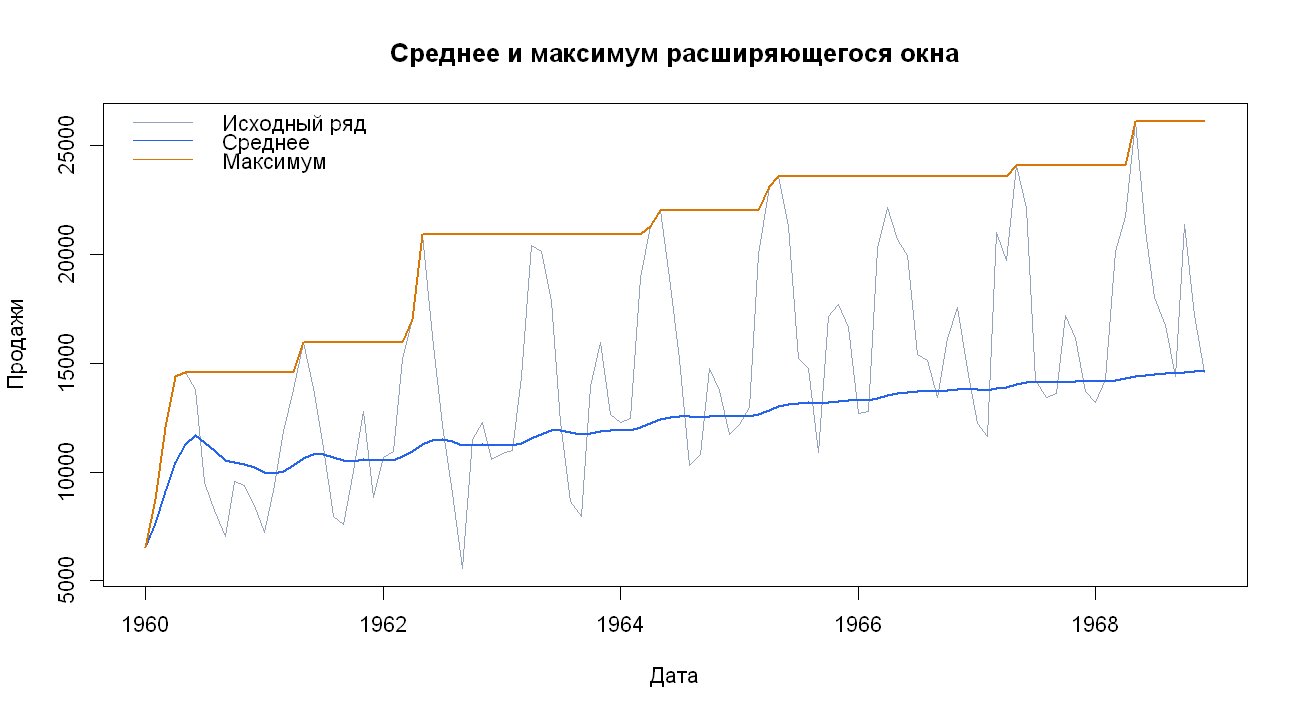

In [12]:
expanding_mean <- cumsum(sales) / seq_along(sales)
expanding_max <- rollapply(zoo(sales), seq_along(sales), max, align = "right")
plot(data$Month, sales, type = "l", col = "#94A3B8", xlab = "Дата", ylab = "Продажи",
     main = "Среднее и максимум расширяющегося окна")
lines(data$Month, expanding_mean, col = "#2563EB", lwd = 2)
lines(data$Month, as.numeric(expanding_max), col = "#D97706", lwd = 2)
legend("topleft", c("Исходный ряд", "Среднее", "Максимум"),
       col = c("#94A3B8", "#2563EB", "#D97706"), lty = 1, bty = "n")

## 12 Пользовательская оконная функция

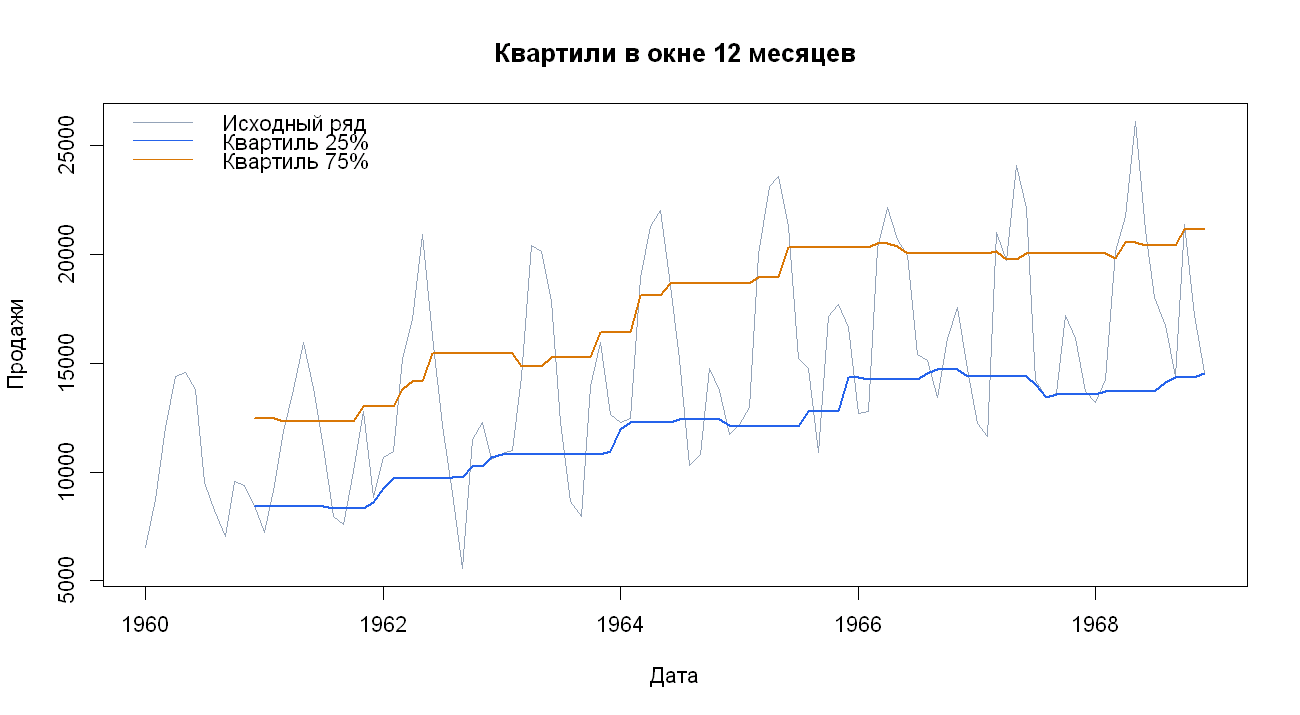

In [13]:
quartiles <- rollapply(sales_zoo, 12, function(x) {
    quantile(x, probs = c(0.25, 0.75), names = FALSE)
}, align = "right", fill = NA)
plot(sales_zoo, col = "#94A3B8", xlab = "Дата", ylab = "Продажи",
     main = "Квартили в окне 12 месяцев")
lines(quartiles[, 1], col = "#2563EB", lwd = 2)
lines(quartiles[, 2], col = "#D97706", lwd = 2)
legend("topleft", c("Исходный ряд", "Квартиль 25%", "Квартиль 75%"),
       col = c("#94A3B8", "#2563EB", "#D97706"), lty = 1, bty = "n")

## 13 Автокорреляция и частная автокорреляция

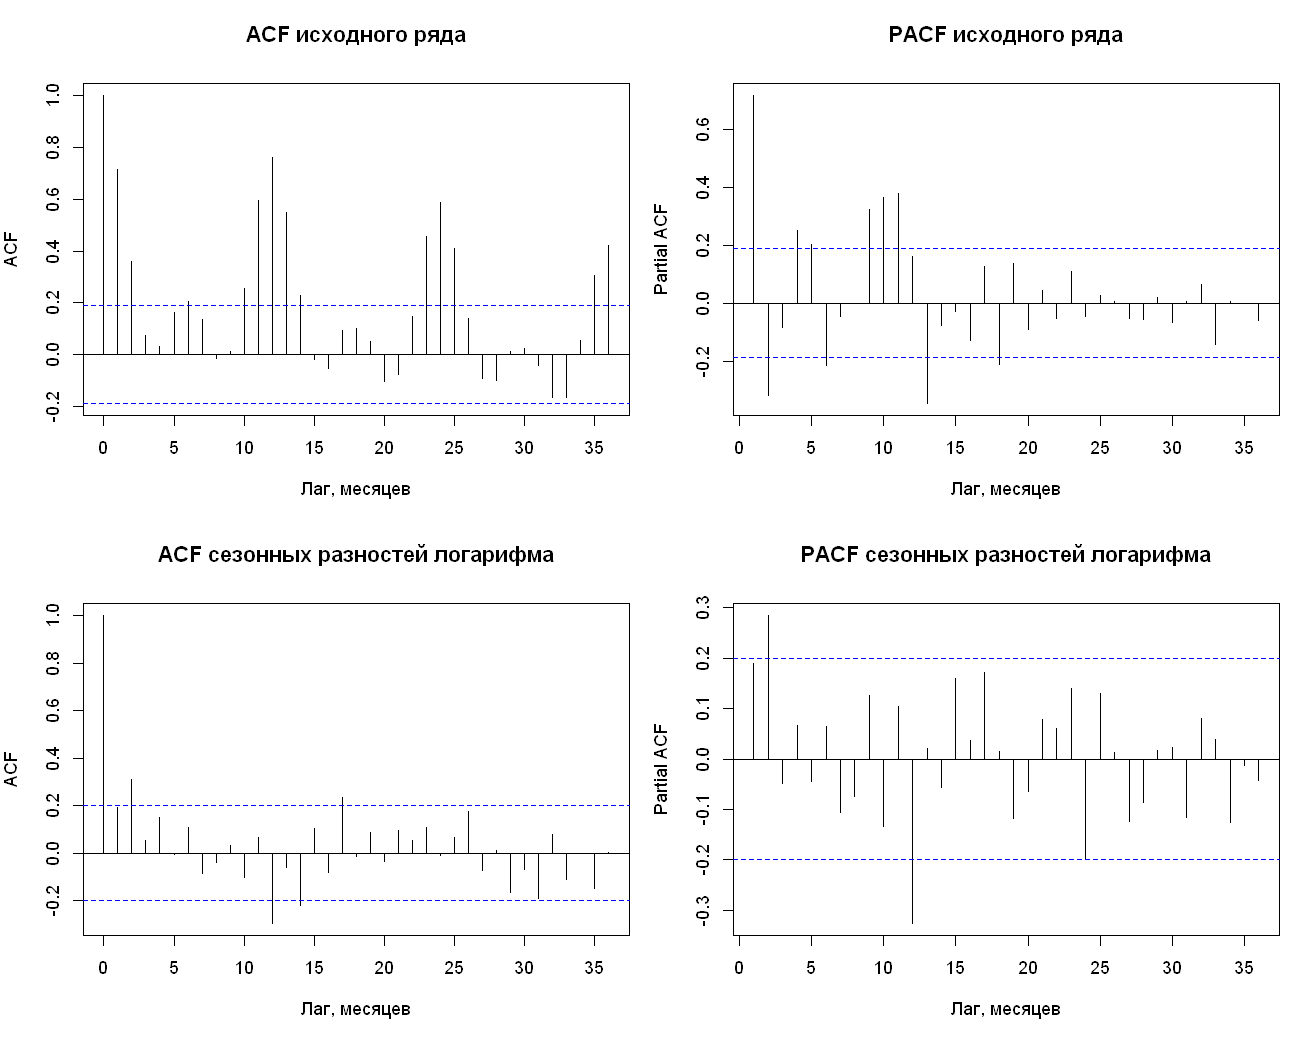

In [14]:
options(repr.plot.height = 8)
par(mfrow = c(2, 2), mar = c(5, 4, 4, 1))
acf(sales, lag.max = 36, main = "ACF исходного ряда", xlab = "Лаг, месяцев")
pacf(sales, lag.max = 36, main = "PACF исходного ряда", xlab = "Лаг, месяцев")
acf(as.numeric(seasonal_log_diff), lag.max = 36, main = "ACF сезонных разностей логарифма", xlab = "Лаг, месяцев")
pacf(as.numeric(seasonal_log_diff), lag.max = 36, main = "PACF сезонных разностей логарифма", xlab = "Лаг, месяцев")
par(mfrow = c(1, 1))
options(repr.plot.height = 5.5)

## 14 Сравнение ACF и корреляции со сдвигом

In [15]:
n <- length(sales)
centered <- sales - mean(sales)
acf_manual <- sapply(1:2, function(k) {
    sum(centered[(k + 1):n] * centered[1:(n - k)]) / sum(centered^2)
})
data.frame(
    Лаг = 1:2,
    Корреляция_Пирсона = sapply(1:2, function(k) cor(sales[1:(n - k)], sales[(k + 1):n])),
    ACF_вручную = acf_manual,
    ACF_функция = as.numeric(acf(sales, lag.max = 2, plot = FALSE)$acf)[2:3]
)

Лаг,Корреляция_Пирсона,ACF_вручную,ACF_функция
<int>,<dbl>,<dbl>,<dbl>
1,0.7280681,0.7171326,0.7171326
2,0.3676448,0.3583670,0.3583670


## 15 Периодические ряды без шума

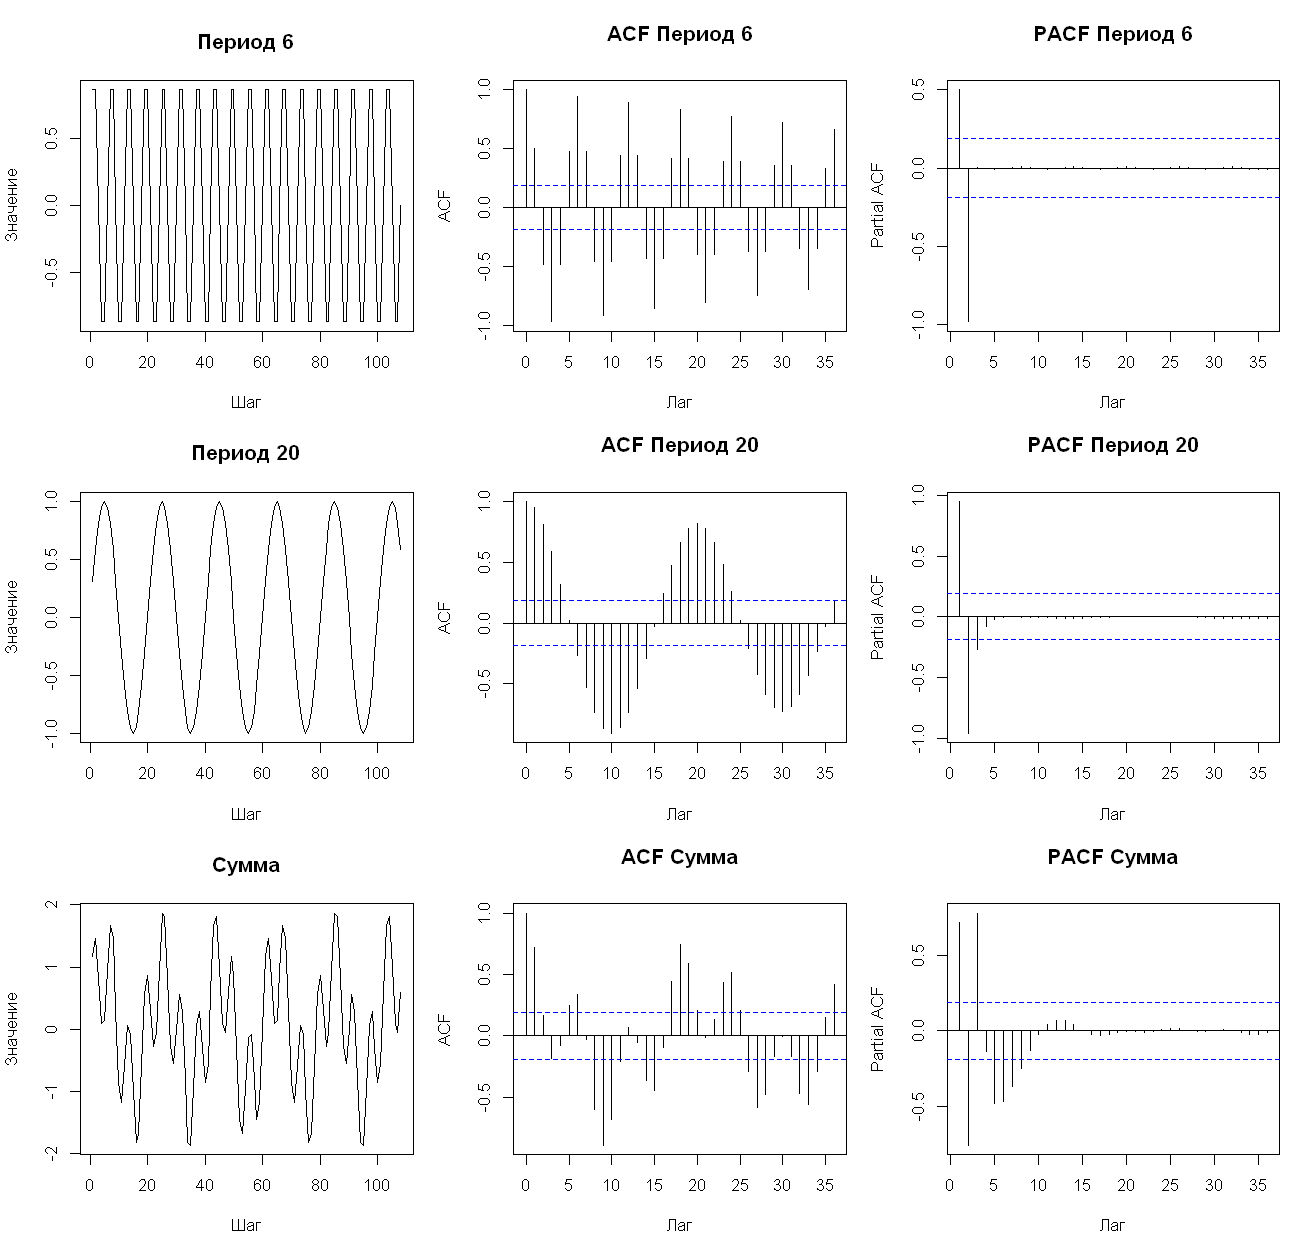

In [16]:
t <- seq_along(sales)
wave_1 <- sin(2 * pi * t / 6)
wave_2 <- sin(2 * pi * t / 20)
show_correlations <- function(series) {
    par(mfrow = c(3, 3), mar = c(4, 4, 4, 1), cex = 0.8)
    for (name in names(series)) {
        x <- series[[name]]
        plot(x, type = "l", main = name, xlab = "Шаг", ylab = "Значение")
        acf(x, lag.max = 36, main = paste("ACF", name), xlab = "Лаг")
        pacf(x, lag.max = 36, main = paste("PACF", name), xlab = "Лаг")
    }
    par(mfrow = c(1, 1), cex = 1)
}
options(repr.plot.height = 9.5)
show_correlations(list("Период 6" = wave_1, "Период 20" = wave_2, "Сумма" = wave_1 + wave_2))

## 16 Слабый шум

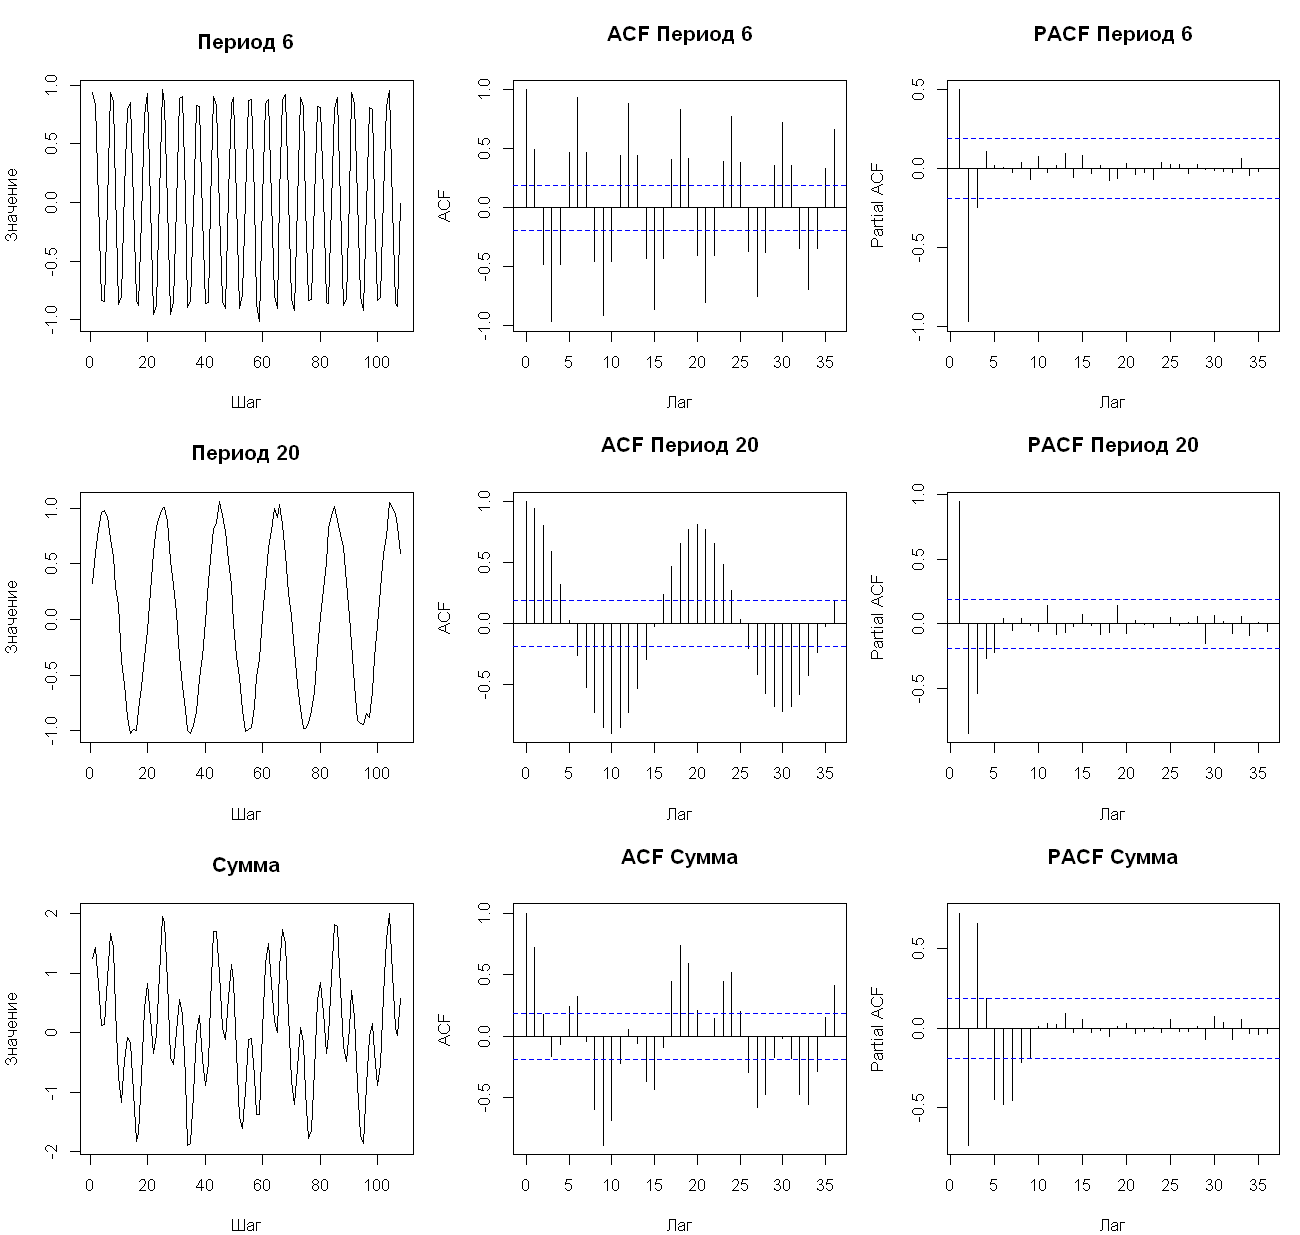

In [17]:
set.seed(42)
# Добавил воспроизводимый шум к исходным синусоидам.
weak_1 <- wave_1 + rnorm(n, sd = 0.05)
weak_2 <- wave_2 + rnorm(n, sd = 0.05)
show_correlations(list("Период 6" = weak_1, "Период 20" = weak_2, "Сумма" = weak_1 + weak_2))

## 17 Сильный шум

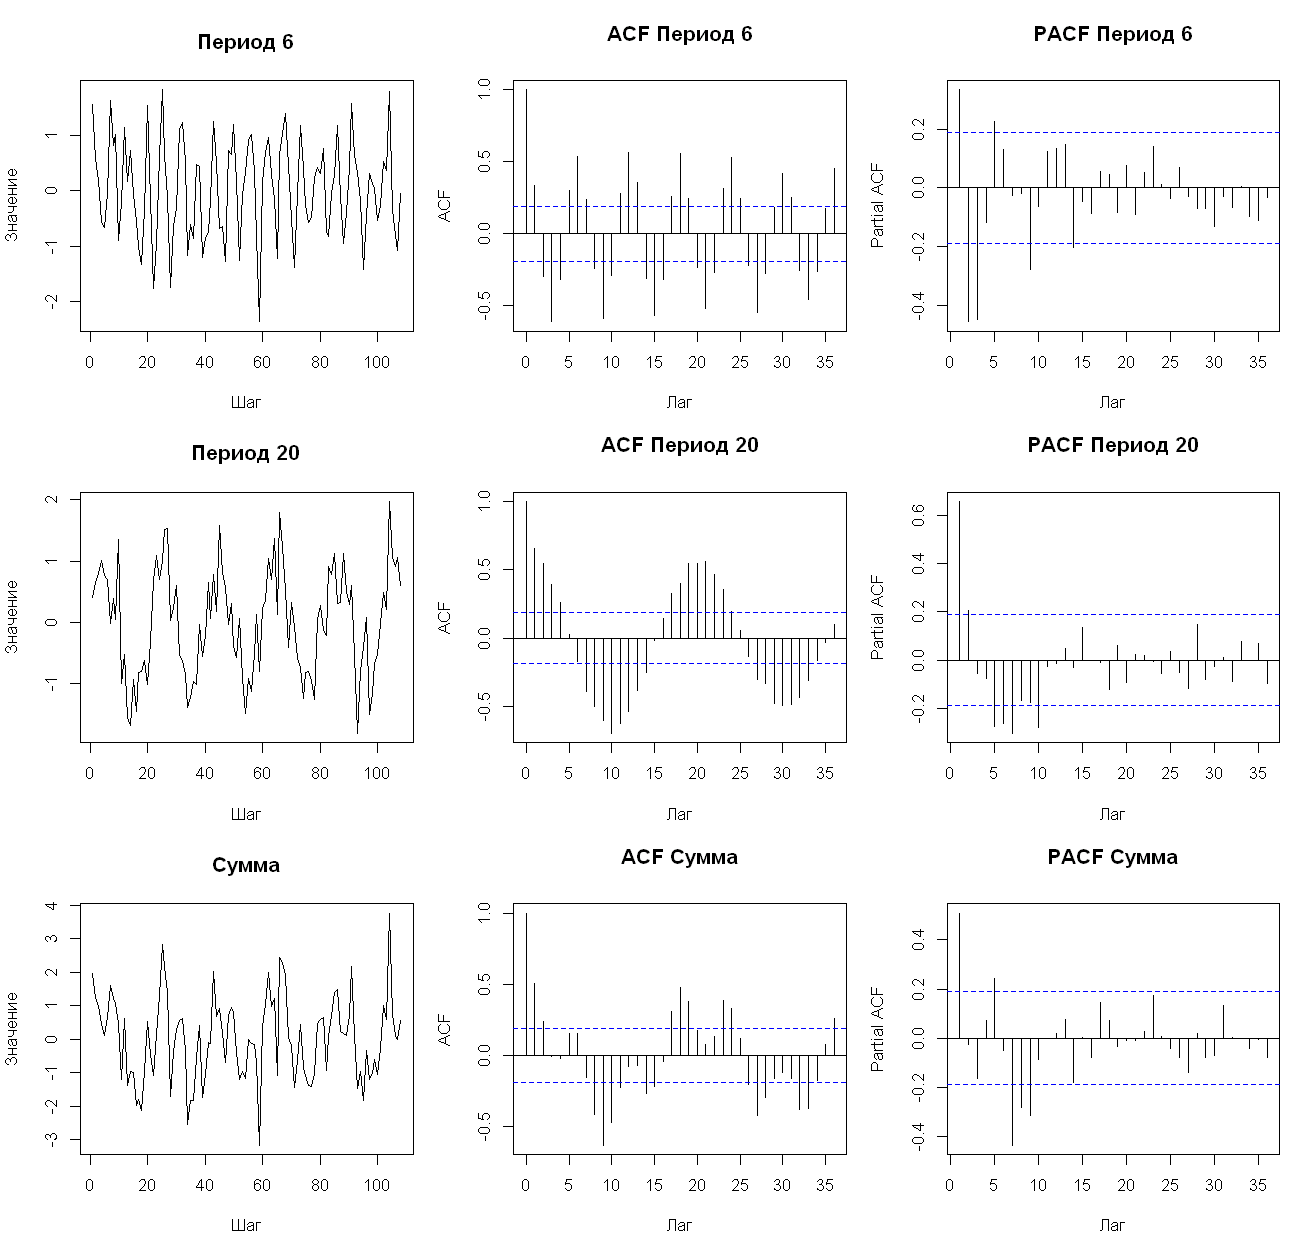

In [18]:
set.seed(42)
strong_1 <- wave_1 + rnorm(n, sd = 0.5)
strong_2 <- wave_2 + rnorm(n, sd = 0.5)
show_correlations(list("Период 6" = strong_1, "Период 20" = strong_2, "Сумма" = strong_1 + strong_2))
options(repr.plot.height = 5.5)

## 18 Ряд с линейным трендом

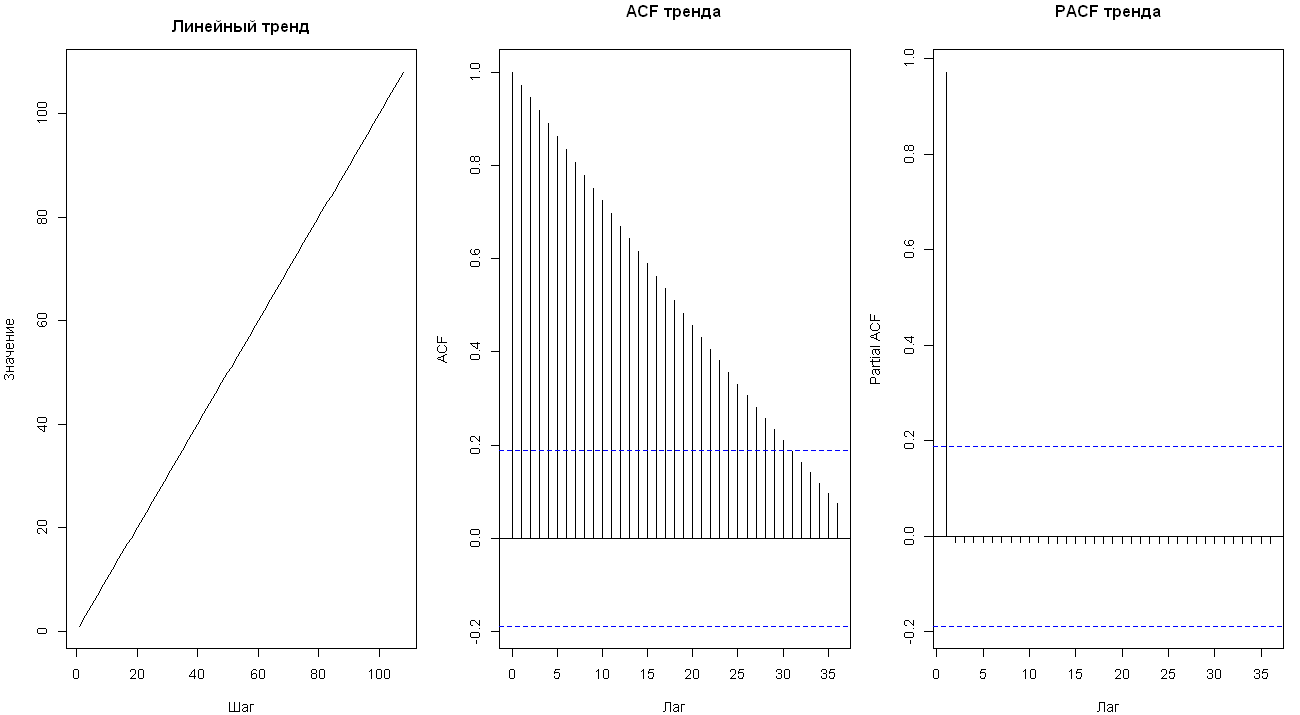

In [19]:
trend_series <- seq_len(n)
par(mfrow = c(1, 3), mar = c(4, 4, 3, 1))
plot(trend_series, type = "l", main = "Линейный тренд", xlab = "Шаг", ylab = "Значение")
acf(trend_series, lag.max = 36, main = "ACF тренда", xlab = "Лаг")
pacf(trend_series, lag.max = 36, main = "PACF тренда", xlab = "Лаг")
par(mfrow = c(1, 1))

## 19 Ложная корреляция на моделируемых рядах

Представление,Корреляция
<chr>,<dbl>
Уровни,0.9821975
Разности,0.0492613


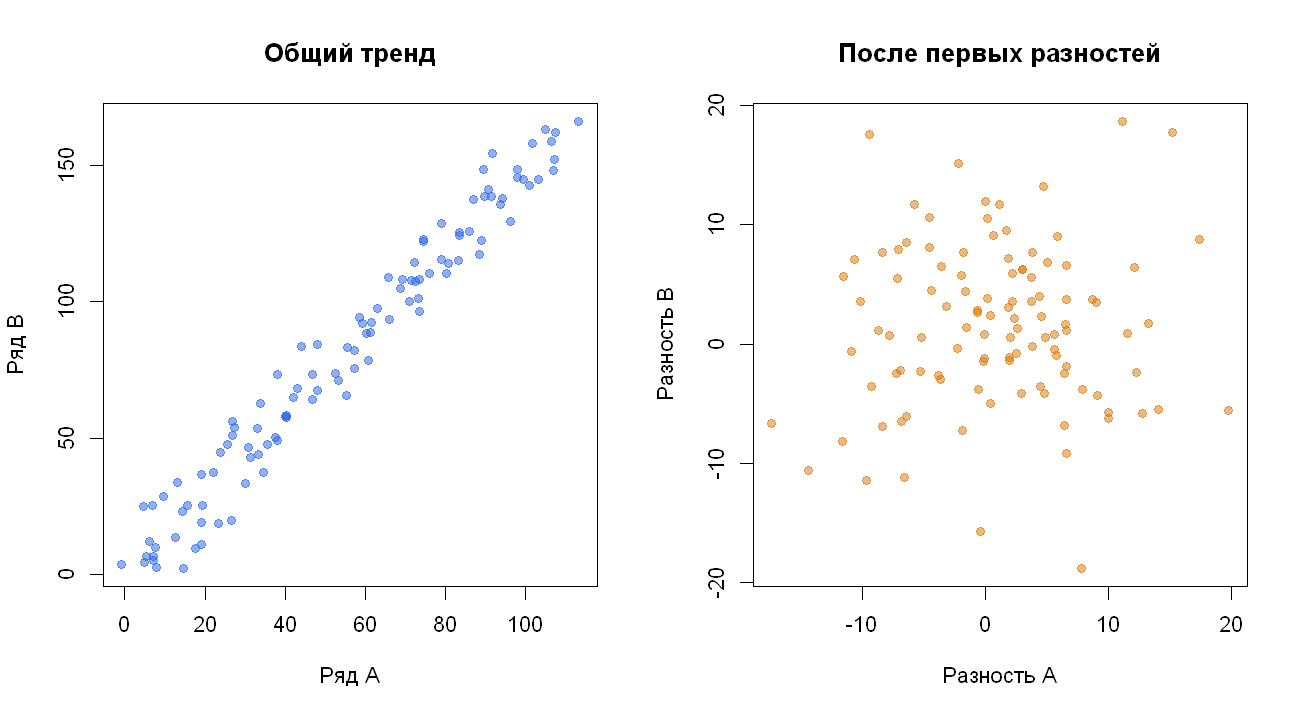

In [20]:
set.seed(42)
series_a <- t + rnorm(n, sd = 5)
series_b <- 1.5 * t + rnorm(n, sd = 5)
par(mfrow = c(1, 2))
plot(series_a, series_b, pch = 19, col = "#2563EB80", main = "Общий тренд",
     xlab = "Ряд A", ylab = "Ряд B")
plot(diff(series_a), diff(series_b), pch = 19, col = "#D9770680",
     main = "После первых разностей", xlab = "Разность A", ylab = "Разность B")
par(mfrow = c(1, 1))
data.frame(
    Представление = c("Уровни", "Разности"),
    Корреляция = c(cor(series_a, series_b), cor(diff(series_a), diff(series_b)))
)

## 20 Коинтеграция на моделируемых рядах

Ряд,ADF_p,KPSS_p,Вывод
<chr>,<chr>,<chr>,<chr>
X,0.5755,0.0836,Нет однозначного вывода
Y,0.5969,0.0836,Нет однозначного вывода
Y - 1.7 X,<= 0.01,>= 0.1,Не противоречит стационарности


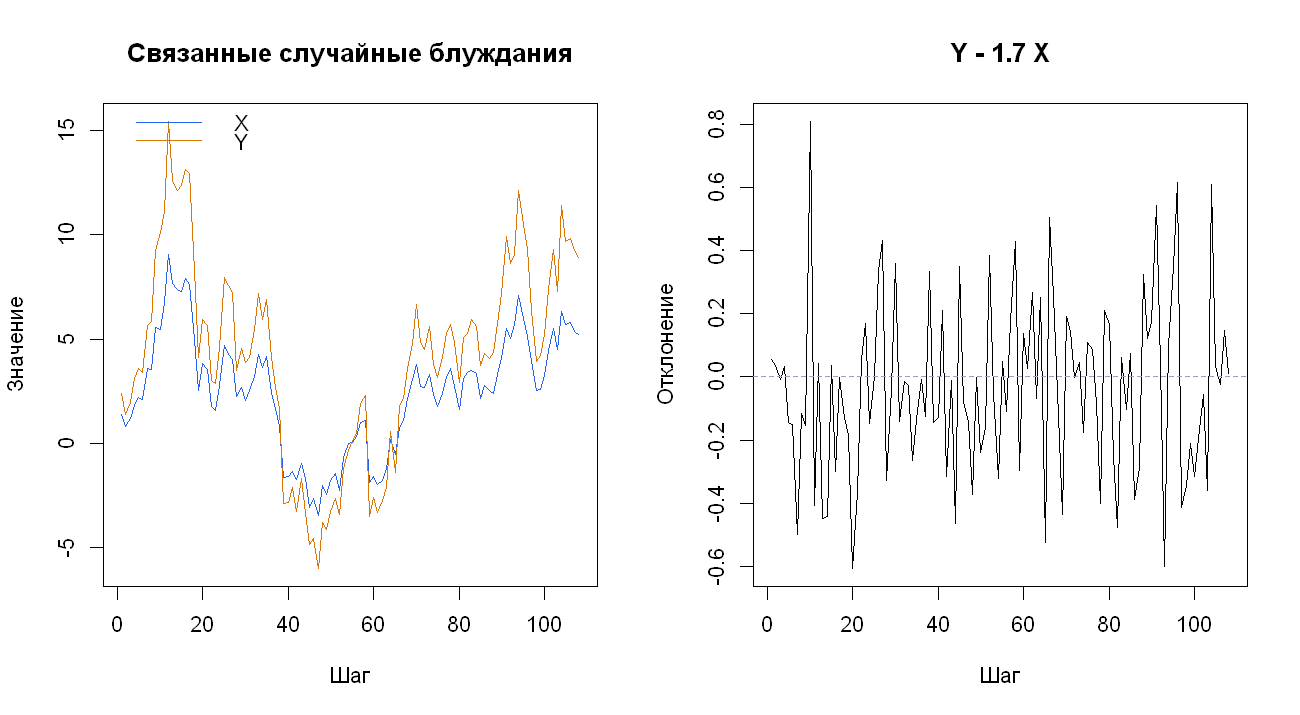

In [21]:
set.seed(42)
walk <- cumsum(rnorm(n))
linked <- 1.7 * walk + rnorm(n, sd = 0.3)
spread <- linked - 1.7 * walk
par(mfrow = c(1, 2))
matplot(cbind(walk, linked), type = "l", lty = 1, col = c("#2563EB", "#D97706"),
        main = "Связанные случайные блуждания", xlab = "Шаг", ylab = "Значение")
legend("topleft", c("X", "Y"), col = c("#2563EB", "#D97706"), lty = 1, bty = "n")
plot(spread, type = "l", main = "Y - 1.7 X", xlab = "Шаг", ylab = "Отклонение")
abline(h = 0, col = "#94A3B8", lty = 2)
par(mfrow = c(1, 1))
do.call(rbind, lapply(c("X", "Y", "Y - 1.7 X"), function(name) {
    x <- switch(name, "X" = walk, "Y" = linked, "Y - 1.7 X" = spread)
    check_stationarity(x, name)
}))